**Практическая работа №4**

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

импортировала необходимые библиотеки

In [2]:
df = pd.read_csv("titanic.csv")

загрузила titanic.csv

In [3]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


вывела первые 5 строк

In [5]:
X = df[["Pclass", "Age", "Sex", "Fare", "SibSp", "Parch"]]
X.head()

,Pclass,Age,Sex,Fare,SibSp,Parch
0,3,22.0,male,7.2500,1,0
1,1,38.0,female,71.2833,1,0
2,3,26.0,female,7.9250,0,0
3,1,35.0,female,53.1000,1,0
4,3,35.0,male,8.0500,0,0


создала x

In [4]:
y = df["Survived"]
y.head()

,Survived
0,0
1,1
2,1
3,1
4,0


создала y

In [6]:
X.isnull().sum()

,0
Pclass,0
Age,177
Sex,0
Fare,0
SibSp,0
Parch,0


проверила пропущенные значения

In [7]:
X["Age"].median()

28.0

In [8]:
X["Age"] = X["Age"].fillna(X["Age"].median())

/tmp/ipykernel_2788/2770350965.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X["Age"] = X["Age"].fillna(X["Age"].median())


In [9]:
X.isnull().sum()

,0
Pclass,0
Age,0
Sex,0
Fare,0
SibSp,0
Parch,0


обработала пропуски в age

In [10]:
X["Sex"] = X["Sex"].map({
    "male": 0,
    "female": 1
})

/tmp/ipykernel_2788/3323189253.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X["Sex"] = X["Sex"].map({


In [11]:
X.head()

,Pclass,Age,Sex,Fare,SibSp,Parch
0,3,22.0,0,7.2500,1,0
1,1,38.0,1,71.2833,1,0
2,3,26.0,1,7.9250,0,0
3,1,35.0,1,53.1000,1,0
4,3,35.0,0,8.0500,0,0


преобразовала Sex в числовой вид

In [12]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Pclass  891 non-null    int64  
 1   Age     891 non-null    float64
 2   Sex     891 non-null    int64  
 3   Fare    891 non-null    float64
 4   SibSp   891 non-null    int64  
 5   Parch   891 non-null    int64  
dtypes: float64(2), int64(4)
memory usage: 41.9 KB


In [13]:
X.isnull().sum()

,0
Pclass,0
Age,0
Sex,0
Fare,0
SibSp,0
Parch,0


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

разделила данные на обучающую и тестовую выборки

In [15]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (712, 6)
X_test: (179, 6)
y_train: (712,)
y_test: (179,)


вывела размеры полученных наборов данных

In [16]:
scaler = StandardScaler()

In [17]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

выполнила масштабирование

**Практическая работа №5**

In [21]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

%matplotlib inline
sns.set(style="whitegrid")

In [22]:
df = pd.read_csv('titanic.csv')

In [24]:
features = ['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch']

In [25]:
target = 'Survived'

data = df[features + [target]].copy()

In [26]:
print("Пропущенные значения до обработки:")
print(data.isnull().sum())

Пропущенные значения до обработки:
Pclass        0
Age         177
Sex           0
Fare          0
SibSp         0
Parch         0
Survived      0
dtype: int64


In [27]:
data['Age'] = data['Age'].fillna(data['Age'].median())

print("Пропущенные значения после обработки:")
print(data.isnull().sum())

Пропущенные значения после обработки:
Pclass      0
Age         0
Sex         0
Fare        0
SibSp       0
Parch       0
Survived    0
dtype: int64


In [28]:
data['Sex'] = data['Sex'].map({'male': 0, 'female': 1})

In [29]:
print("Столбцы таблицы:", list(data.columns))
print("\nТипы данных:")
print(data.dtypes)
print("\nПропущенные значения:", data.isnull().sum().sum())
print("\nРазмер таблицы:", data.shape)

Столбцы таблицы: ['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch', 'Survived']

Типы данных:
Pclass        int64
Age         float64
Sex           int64
Fare        float64
SibSp         int64
Parch         int64
Survived      int64
dtype: object

Пропущенные значения: 0

Размер таблицы: (891, 7)


In [30]:
print("Первые 5 строк подготовленной таблицы:")
print(data.head())

Первые 5 строк подготовленной таблицы:
   Pclass   Age  Sex     Fare  SibSp  Parch  Survived
0       3  22.0    0   7.2500      1      0         0
1       1  38.0    1  71.2833      1      0         1
2       3  26.0    1   7.9250      0      0         1
3       1  35.0    1  53.1000      1      0         1
4       3  35.0    0   8.0500      0      0         0


In [31]:
corr_matrix = data.corr()

In [32]:
print("Корреляционная матрица:")
print(corr_matrix.round(2))

Корреляционная матрица:
          Pclass   Age   Sex  Fare  SibSp  Parch  Survived
Pclass      1.00 -0.34 -0.13 -0.55   0.08   0.02     -0.34
Age        -0.34  1.00 -0.08  0.10  -0.23  -0.17     -0.06
Sex        -0.13 -0.08  1.00  0.18   0.11   0.25      0.54
Fare       -0.55  0.10  0.18  1.00   0.16   0.22      0.26
SibSp       0.08 -0.23  0.11  0.16   1.00   0.41     -0.04
Parch       0.02 -0.17  0.25  0.22   0.41   1.00      0.08
Survived   -0.34 -0.06  0.54  0.26  -0.04   0.08      1.00


In [33]:
corr_matrix_rounded = corr_matrix.round(2)
print(corr_matrix_rounded)

          Pclass   Age   Sex  Fare  SibSp  Parch  Survived
Pclass      1.00 -0.34 -0.13 -0.55   0.08   0.02     -0.34
Age        -0.34  1.00 -0.08  0.10  -0.23  -0.17     -0.06
Sex        -0.13 -0.08  1.00  0.18   0.11   0.25      0.54
Fare       -0.55  0.10  0.18  1.00   0.16   0.22      0.26
SibSp       0.08 -0.23  0.11  0.16   1.00   0.41     -0.04
Parch       0.02 -0.17  0.25  0.22   0.41   1.00      0.08
Survived   -0.34 -0.06  0.54  0.26  -0.04   0.08      1.00


In [34]:
survived_corr = corr_matrix['Survived'].drop('Survived')
print("Корреляция признаков с Survived:")
print(survived_corr.round(2))

Корреляция признаков с Survived:
Pclass   -0.34
Age      -0.06
Sex       0.54
Fare      0.26
SibSp    -0.04
Parch     0.08
Name: Survived, dtype: float64


In [35]:
most_positive = survived_corr.idxmax()
print(f"Наиболее сильная положительная корреляция: {most_positive} ({survived_corr[most_positive]:.2f})")

Наиболее сильная положительная корреляция: Sex (0.54)


In [36]:
most_negative = survived_corr.idxmin()
print(f"Наиболее сильная отрицательная корреляция: {most_negative} ({survived_corr[most_negative]:.2f})")

Наиболее сильная отрицательная корреляция: Pclass (-0.34)


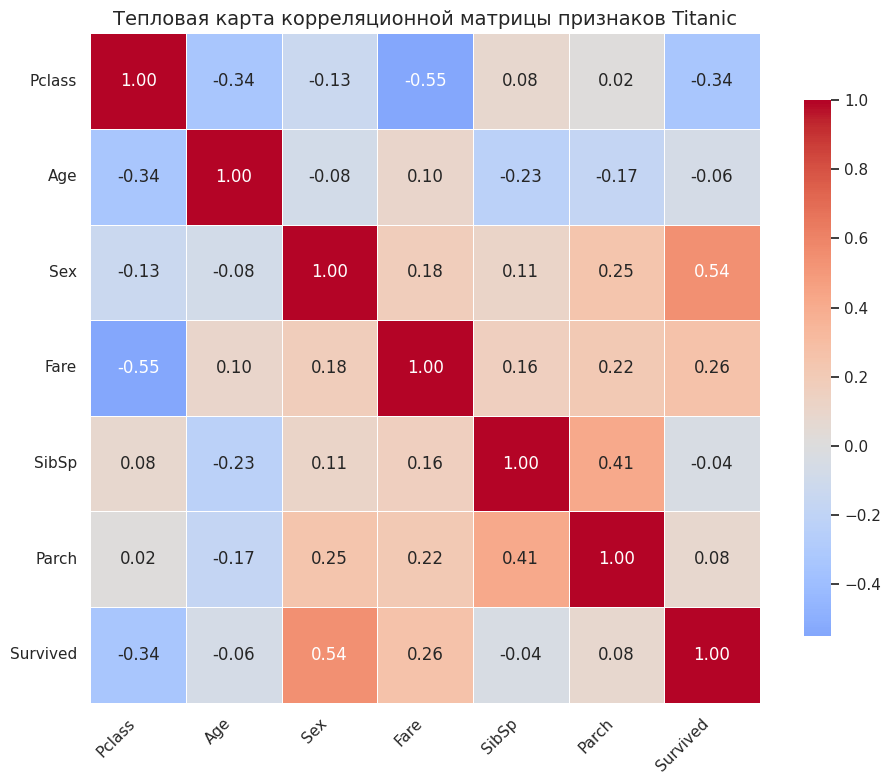

In [38]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8}
)

plt.title('Тепловая карта корреляционной матрицы признаков Titanic', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**Ответы на вопросы по тепловой карте:**

1)Какую функцию библиотеки seaborn необходимо использовать?

-sns.heatmap()


2)Какие данные передать в эту функцию?

-Корреляционную матрицу corr_matrix (результат data.corr())


3)Какой параметр позволит вывести значения коэффициентов внутри ячеек?

-annot=True


4)Какой параметр отвечает за цветовую палитру?

-cmap='coolwarm'


5)Как задать размер графика?

-plt.figure(figsize=(10, 8)) перед вызовом sns.heatmap()

**Какие признаки могут быть наиболее полезны для предсказания Survived?**

Наиболее полезны Sex, Pclass и Fare. Пол и класс — сильнее всего связаны с выживанием: женщины и пассажиры 1-го класса выживали чаще. Остальные признаки (Age, SibSp, Parch) показали слабую линейную связь.

**Можно ли выбирать признаки только на основании корреляции?**

Нет. Корреляция Пирсона отражает только линейную связь, не учитывает взаимодействия признаков и нелинейные зависимости, а также не говорит о причинно-следственной связи. Корреляцию можно использовать как первичный ориентир, но окончательный отбор признаков следует проводить с помощью моделей машинного обучения и кросс-валидации.

**Практическая работа №6**

In [20]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("titanic.csv")
print(df.head())

features = ["Pclass", "Age", "Sex", "Fare", "SibSp", "Parch"]
X = df[features].copy()
y = df["Survived"]

X["Age"] = X["Age"].fillna(X["Age"].median())
X["Sex"] = X["Sex"].map({"male": 0, "female": 1})

print(X.isnull().sum())
print(X.dtypes)

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
Pc

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Размер X_train:", X_train.shape)  # (712, 6) ≈ 80%
print("Размер X_test:", X_test.shape)    # (179, 6) ≈ 20%

Размер X_train: (712, 6)
Размер X_test: (179, 6)


**Ответы на вопросы:**

Тестовая выборка нужна, чтобы оценить модель на данных, которые она не видела при обучении. Иначе оценка будет завышенной — модель просто «запомнит» ответы.

fit_transform() только для train: параметры масштабирования (среднее, std) вычисляются только по обучающим данным, чтобы не «подглядывать» в тест. К тесту применяем уже обученный scaler через transform().

In [22]:
from sklearn.linear_model import LogisticRegression

model_lr = LogisticRegression(max_iter=1000)
model_lr.fit(X_train_scaled, y_train)

y_pred_lr = model_lr.predict(X_test_scaled)

print("Первые предсказания:", y_pred_lr[:10])
print("Правильные ответы:", y_test.iloc[:10].to_list())

Первые предсказания: [0 0 0 0 1 0 1 0 0 0]
Правильные ответы: [0, 0, 1, 0, 1, 1, 1, 0, 0, 0]


Совпали позиции 0, 1, 3, 4, 6, 7, 8, 9. Ошибки: позиция 2 (предсказано 0, реально 1) и позиция 5 (предсказано 0, реально 1). 0 — пассажир не выжил, 1 — выжил.

In [23]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1:", f1_score(y_test, y_pred_lr))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred_lr))
print("\n", classification_report(y_test, y_pred_lr))

Accuracy: 0.8044692737430168
Precision: 0.765625
Recall: 0.7101449275362319
F1: 0.7368421052631579
Confusion matrix:
 [[95 15]
 [20 49]]

               precision    recall  f1-score   support

           0       0.83      0.86      0.84       110
           1       0.77      0.71      0.74        69

    accuracy                           0.80       179
   macro avg       0.80      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



**Ответы:**

Доля правильных предсказаний — Accuracy.

Насколько модель находит реально выживших — Recall (полнота).

FP (ложноположительные): модель сказала «выжил», а на самом деле погиб. FN (ложноотрицательные): модель сказала «погиб», а на самом деле выжил.

In [24]:
from sklearn.tree import DecisionTreeClassifier

model_tree = DecisionTreeClassifier(max_depth=4, random_state=42)
model_tree.fit(X_train, y_train)

y_pred_tree = model_tree.predict(X_test)

print("Accuracy дерева:", accuracy_score(y_test, y_pred_tree))
print("Precision дерева:", precision_score(y_test, y_pred_tree))
print("Recall дерева:", recall_score(y_test, y_pred_tree))
print("F1 дерева:", f1_score(y_test, y_pred_tree))
print("Confusion matrix дерева:\n", confusion_matrix(y_test, y_pred_tree))

Accuracy дерева: 0.7821229050279329
Precision дерева: 0.875
Recall дерева: 0.5072463768115942
F1 дерева: 0.6422018348623854
Confusion matrix дерева:
 [[105   5]
 [ 34  35]]


Логистическая регрессия: Accuracy 0.804, Precision 0.766, Recall 0.710, F1 0.737. Дерево решений: Accuracy 0.782, Precision 0.875, Recall 0.507, F1 0.642. Логистическая регрессия лучше по Accuracy, Recall и F1 — она находит больше реально выживших (recall 0.71 против 0.51). Дерево точнее в положительных предсказаниях (precision 0.875), но пропускает много выживших (FN: 34 против 20). Для задачи выживаемости важнее Recall, поэтому логистическая регрессия предпочтительнее.

In [25]:
corr = df[["Survived", "Pclass", "Age", "Sex", "Fare", "SibSp", "Parch"]].copy()
corr["Sex"] = corr["Sex"].map({"male": 0, "female": 1})

corr_matrix = corr.corr()
print(corr_matrix["Survived"].sort_values(ascending=False))

Survived    1.000000
Sex         0.543351
Fare        0.257307
Parch       0.081629
SibSp      -0.035322
Age        -0.077221
Pclass     -0.338481
Name: Survived, dtype: float64


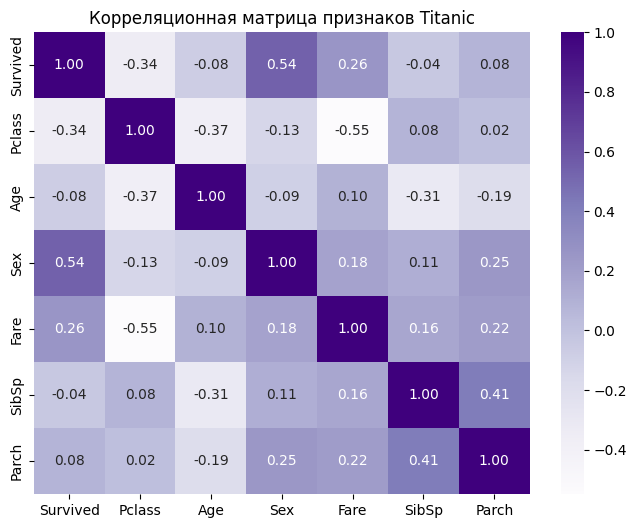

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="Purples")
plt.title("Корреляционная матрица признаков Titanic")
plt.show()

Вывод: данные подготовлены (пропуски Age заполнены медианой, Sex закодирован), выполнено разделение 80/20 со стратификацией. Корреляционный анализ: сильнейшая положительная связь с Survived у пола (Sex, 0.54), сильнейшая отрицательная — у класса (Pclass, −0.34). Логистическая регрессия предсказывает выживаемость с accuracy ≈ 0.80, дерево решений — ≈ 0.78. Модель предсказывает удовлетворительно, но recall по выжившим (0.71) означает, что примерно треть реально выживших она пропускает. Качество можно улучшить добавлением признаков (Embarked, Cabin, размер семьи) и подбором гиперпараметров.